In [2]:
import scanpy as sc
print(sc.__version__)

1.12.4


/tmp/ipykernel_905704/289967954.py:2: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  print(sc.__version__)


In [4]:
adata = sc.read_10x_h5 (
    '/scratch/maid/DP2_PBMC/PBMC_rawData/DEL5_Wk0/filtered_feature_bc_matrix.h5',
    gex_only=True
)
adata.var_names_make_unique()
adata

/home/aryan/sc_env/lib/python3.13/site-packages/scanpy/readwrite.py:248: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = adata.copy()


AnnData object with n_obs × n_vars = 13075 × 26530
    var: 'gene_ids', 'feature_types', 'genome', 'interval'
    layers: None (.X)

In [5]:
"""
gene_ids = the ids for each feature
feature_types = the type of each feature, Gene Expression (RNA) or a Peak (ATAC)
genome = which genome the feature is from
interval = the genomic coordinates of the feature

"""

'\ngene_ids = the ids for each feature\nfeature_types = the type of each feature, Gene Expression (RNA) or a Peak (ATAC)\ngenome = which genome the feature is from\ninterval = the genomic coordinates of the feature\n\n'

In [6]:
# RNA vs ATAC split
adata.var['feature_types'].value_counts()

feature_types
Gene Expression    26530
Name: count, dtype: int64

In [7]:
adata.X[:5, :5].toarray()
adata.X.max()

np.float32(1747.0)

In [8]:
adata.var.head()

,gene_ids,feature_types,genome,interval
ENSMMUG00000023296,ENSMMUG00000023296,Gene Expression,Mmul_10,1:26652-26653
ZNF692,ENSMMUG00000000634,Gene Expression,Mmul_10,1:71581-72380
ZNF672,ENSMMUG00000037875,Gene Expression,Mmul_10,1:91015-91679
SH3BP5L,ENSMMUG00000000632,Gene Expression,Mmul_10,1:102661-103200
ENSMMUG00000064799,ENSMMUG00000064799,Gene Expression,Mmul_10,1:124201-124202


In [9]:
#trying to look for mitochondrial genes
print("MT- :", [x for x in adata.var_names if x.startswith('MT-')][:20])
print("mt- :", [x for x in adata.var_names if x.startswith('mt-')][:20])
print("contains MT:", [x for x in adata.var_names if 'MT' in x.upper()][:20])

MT- : []
mt- : []
contains MT: ['MTF2', 'MTF1', 'MTMR11', 'LAMTOR5', 'MTR', 'TRMT1L', 'MTARC2', 'MTHFR', 'HENMT1', 'CAMTA1', 'MTOR', 'PRMT6', 'ICMT', 'LAMTOR2', 'TRMT13', 'NTMT2', 'ADAMTS4', 'MTFR1L', 'ADAMTSL4', 'TRMT10C']


In [10]:
#Mito also identfied by chromosome - interval column
adata.var[adata.var['interval'].str.startswith('MT:', na=False)].head(20)
adata.var['interval'].str.split(":").str[0].value_counts().head(20)

interval
1     2493
7     1749
3     1533
19    1486
14    1479
2     1463
4     1394
16    1380
11    1332
10    1301
6     1251
5     1115
9     1099
X     1048
20    1026
15    1023
8     1014
13     976
12     917
17     534
Name: count, dtype: int64

In [ ]:
adata.var['interval'].str.split(':').str[0].unique()  


#(macaque mito genes: ND1-6, COX1-3, CYTB, ATP6/8)
mito_names = ['ND1','ND2','ND3','ND4','ND4L','ND5','ND6','COX1','COX2','COX3',
              'CYTB','ATP6','ATP8','MT-ND1','MT-CO1']
[g for g in adata.var_names if g in mito_names]

['ND1',
 'ND2',
 'COX1',
 'COX2',
 'ATP8',
 'ATP6',
 'COX3',
 'ND3',
 'ND4L',
 'ND4',
 'ND5',
 'ND6',
 'CYTB']

In [12]:
mito_genes = ['ND1','ND2','ND3','ND4','ND4L','ND5','ND6',
            'COX1','COX2','COX3','ATP6','ATP8','CYTB']

adata.var['mt'] = adata.var_names.isin(mito_genes)
adata.var['mt'].sum()

np.int64(13)

In [13]:
sc.pp.calculate_qc_metrics(
    adata,
    qc_vars=['mt'],
    percent_top=None,
    log1p=False,
    inplace=True
)

#per cell table of QC metrics
adata.obs.head()
adata.obs.columns

Index(['n_genes_by_counts', 'total_counts', 'total_counts_mt',
       'pct_counts_mt'],
      dtype='str')

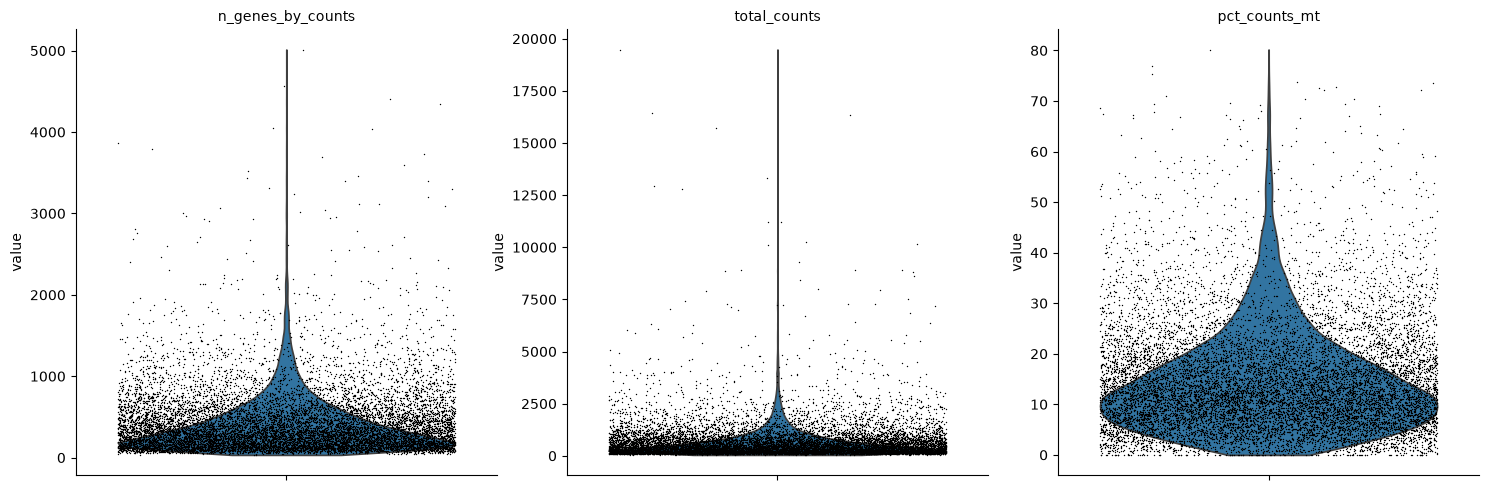

In [15]:
sc.pl.violin(
    adata,
    ['n_genes_by_counts', 'total_counts', 'pct_counts_mt'],
    jitter=0.4,
    multi_panel=True
)

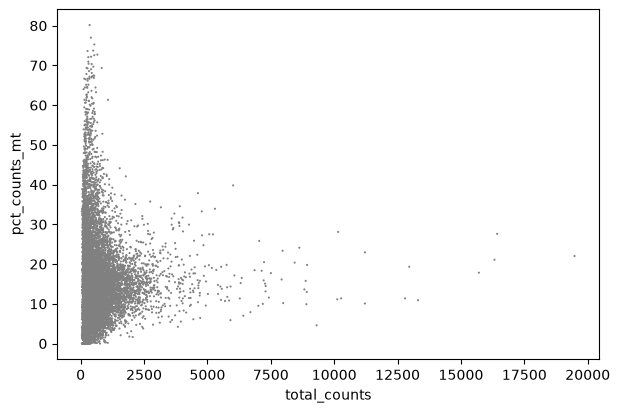

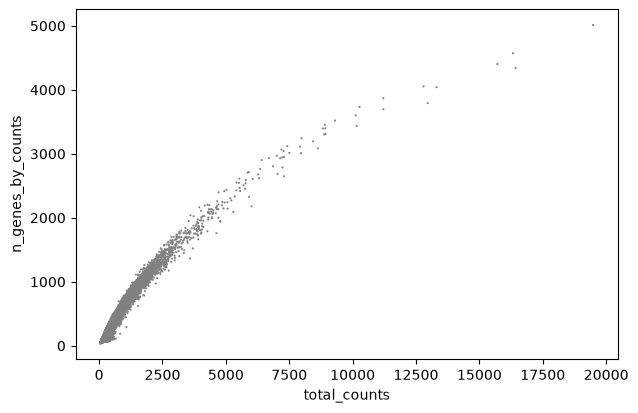

In [16]:
sc.pl.scatter(adata, x='total_counts', y='pct_counts_mt')
sc.pl.scatter(adata, x='total_counts', y='n_genes_by_counts')

In [18]:
adata.write("/home/aryan/hiv-latency-sc/objects/DEL5_Wk0_qc.h5ad")


In [19]:
adata


AnnData object with n_obs × n_vars = 13075 × 26530
    obs: 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt'
    var: 'gene_ids', 'feature_types', 'genome', 'interval', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
    layers: None (.X)

In [20]:
adata.write("/home/aryan/hiv-latency-sc/objects/DEL5_Wk0_qcmetrics.h5ad")